In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression,RidgeClassifier
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

import warnings
warnings.filterwarnings("ignore")


# **1. Data Loading**

In [4]:
df = pd.read_csv("/content/diabetes.csv")
df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [5]:
df.shape

(768, 9)

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [8]:
!pip install ydata-profiling

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 400.8/400.8 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 42.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 682.5/682.5 kB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 2.5 MB/s eta 0:00:00


In [9]:
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Data Profiling Report of Pima Indians Diabetes Dataset", explorative=True)
profile.to_file("Diabetes_Data.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 9/9 [00:00<00:00, 22.09it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [10]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

# **2. Data Preprocessing**

In [11]:
# Handling missing value

zero_cols =['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df[zero_cols] = df[zero_cols].replace(0, np.nan)

#impute
imputer = SimpleImputer(strategy='median')
df[zero_cols] = imputer.fit_transform(df[zero_cols])

In [12]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


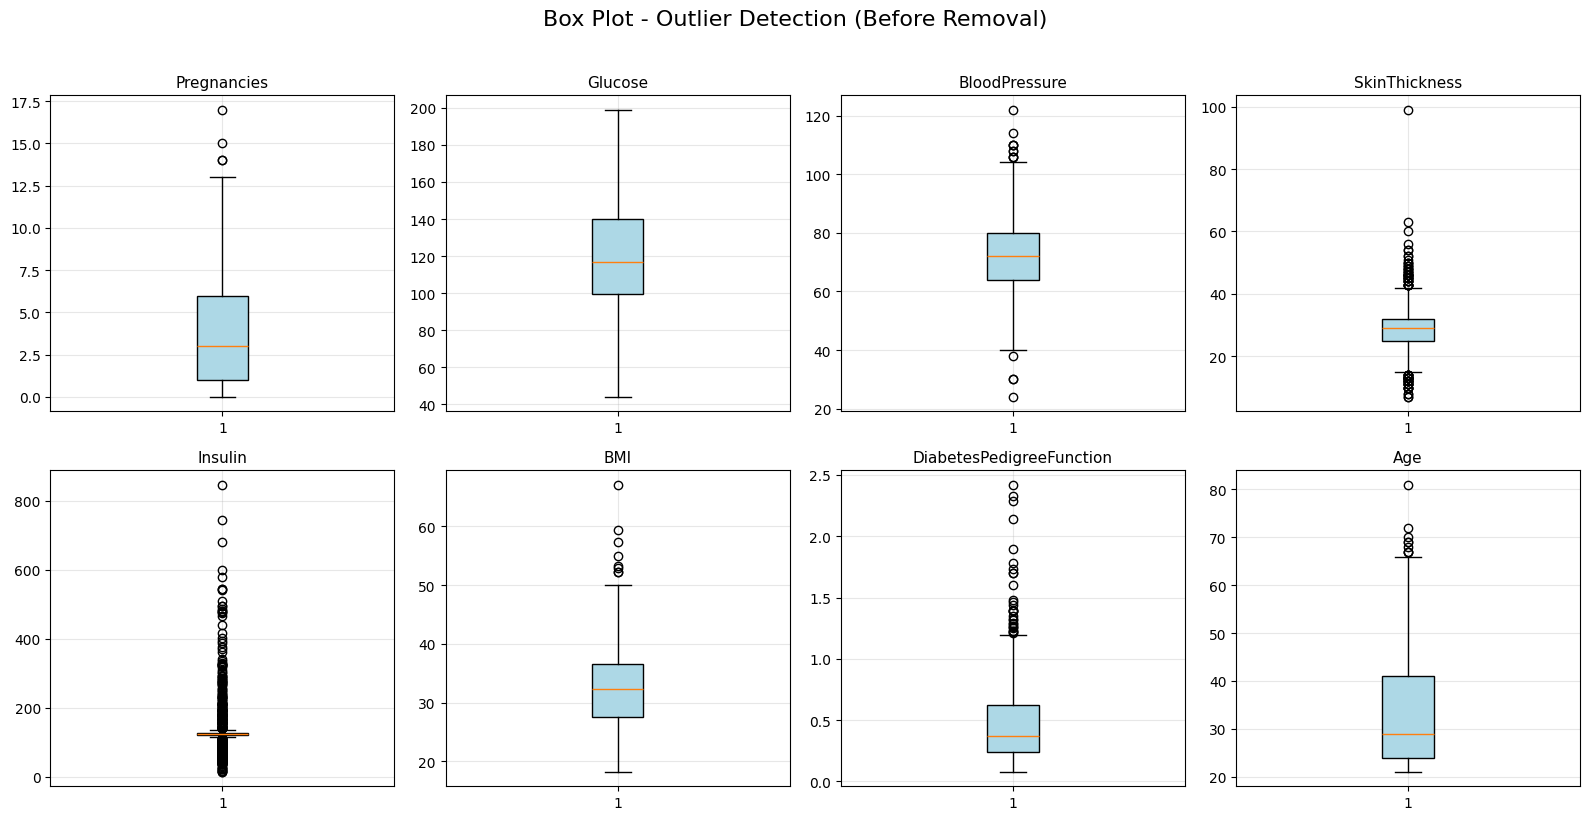

In [13]:
# Outlier Detection
numeric_features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
                    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(numeric_features):
    axes[i].boxplot(df[col], patch_artist=True, boxprops=dict(facecolor='lightblue'))
    axes[i].set_title(col, fontsize=11)
    axes[i].grid(True, alpha=0.3)

plt.suptitle("Box Plot - Outlier Detection (Before Removal)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


Outliers successfully capped


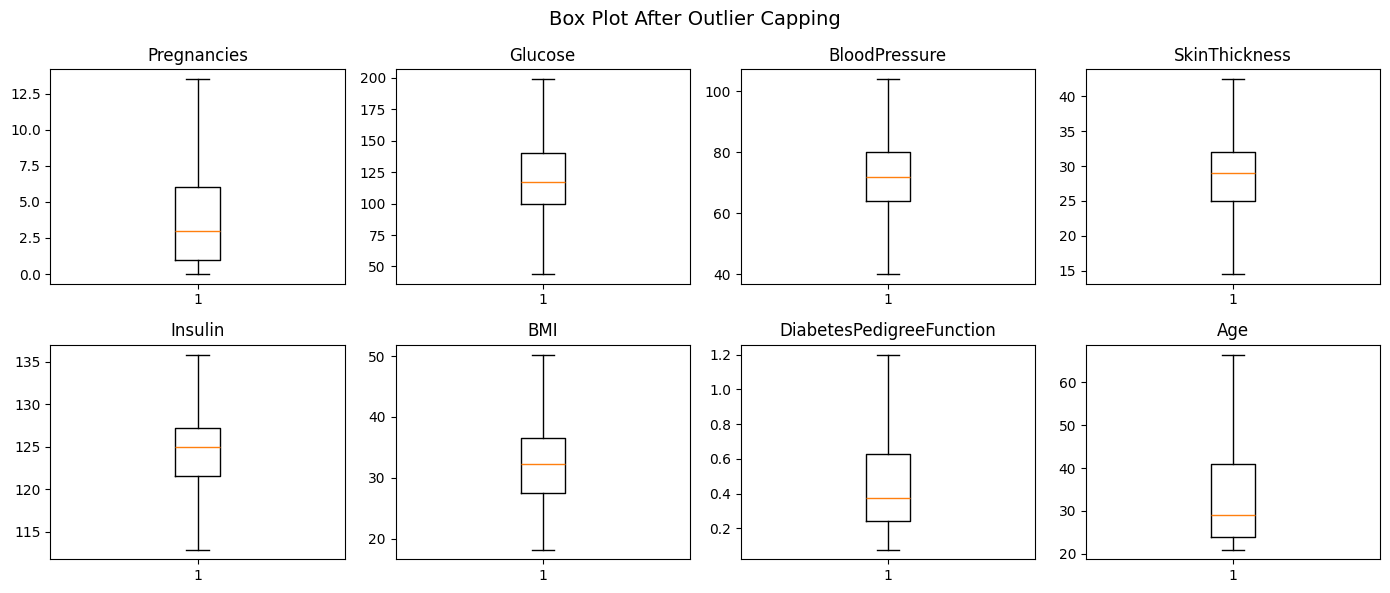

In [14]:
# Handle Outlier

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR


    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

print("Outliers successfully capped")

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.ravel()

for i, col in enumerate(numeric_features):
    axes[i].boxplot(df[col])
    axes[i].set_title(col)

plt.suptitle("Box Plot After Outlier Capping", fontsize=14)
plt.tight_layout()
plt.show()

**Seperate X and y**

In [15]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

In [16]:
# Numeric Features
numeric_features = X.select_dtypes(include=['int64','float64']).columns

numeric_features

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object')

In [17]:

# Split them

X_train, X_test, y_train, y_test = train_test_split( X,y,test_size=0.2,random_state=42)

In [18]:
# 6. Scaling (StandardScaler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(pd.DataFrame(X_train_scaled, columns=X.columns).describe().round(2))

       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
count       614.00   614.00         614.00         614.00   614.00  614.00   
mean          0.00     0.00          -0.00          -0.00    -0.00   -0.00   
std           1.00     1.00           1.00           1.00     1.00    1.00   
min          -1.14    -2.59          -2.75          -1.87    -1.45   -2.10   
25%          -0.83    -0.72          -0.70          -0.61    -1.06   -0.74   
50%          -0.22    -0.16          -0.02           0.06     0.06   -0.04   
75%           0.69     0.57           0.66           0.45     0.65    0.61   
max           2.98     2.57           2.71           1.85     1.41    2.68   

       DiabetesPedigreeFunction     Age  
count                    614.00  614.00  
mean                       0.00   -0.00  
std                        1.00    1.00  
min                       -1.33   -1.05  
25%                       -0.75   -0.78  
50%                       -0.29   -0.34  
75%

# **Pipeline**

In [19]:
# Base Learner
lo_reg = LogisticRegression(max_iter=1000, random_state=42)
rf_clf = RandomForestClassifier(random_state=42)
xgb_clf = XGBClassifier(random_state=42, eval_metric='logloss')

In [20]:
# Voting Classifer

voting_clf = VotingClassifier(
    estimators=[
        ('logreg', lo_reg),
        ('rf', rf_clf),
        ('xgb', xgb_clf)
    ]

)

In [21]:
# Stacking Classifer

stacking_clf = StackingClassifier(
    estimators=[
        ('logreg', lo_reg),
        ('rf', rf_clf),
        ('xgb', xgb_clf)
    ],
    final_estimator=RidgeClassifier(),   # meta-model

)

I used Logistic Regression, Random Forest, and XGBoost because each model learns from the data in a different way. Logistic Regression learns simple linear patterns, Random Forest learns non-linear patterns, and XGBoost learns more complex patterns very effectively.

After that, I applied Voting and Stacking so that the strengths of all three models can work together. This helps reduce weaknesses of individual models — when one model makes mistakes, another model can correct it. As a result, the overall performance usually improves in terms of Accuracy, F1 Score, and AUC.

# **Model Training**

In [22]:
model_to_train = {
    'Logistic Regression': lo_reg,
    'Random Forest': rf_clf,
    'XGBoost': xgb_clf,
    'Voting Classifier': voting_clf,
    'Stacking Classifier': stacking_clf
}


In [23]:
# Train to Evaluation

results = []

for name, model in model_to_train.items():

    # Train on already scaled data
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Evaluate classification metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 Score": f1
    })


results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False)

# Print
print(results_df)

                 Model  Accuracy  Precision    Recall  F1 Score
1        Random Forest  0.772727   0.685185  0.672727  0.678899
4  Stacking Classifier  0.766234   0.679245  0.654545  0.666667
3    Voting Classifier  0.759740   0.660714  0.672727  0.666667
0  Logistic Regression  0.746753   0.648148  0.636364  0.642202
2              XGBoost  0.714286   0.590164  0.654545  0.620690


# **Cross Validation**

In [24]:
from sklearn.model_selection import cross_validate

scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score),
    'recall': make_scorer(recall_score),
    'f1': make_scorer(f1_score)
}

models_to_cv = {
    'Logistic Regression': lo_reg,
    'Random Forest': rf_clf,
    'XGBoost': xgb_clf,
    'Voting Classifier': voting_clf,
    'Stacking Classifier': stacking_clf
}

cv_results = {}

for name, model in models_to_cv.items():
    scores = cross_validate(
        model,
        X_train_scaled,  # scaled training data
        y_train,
        cv=5,            # 5-fold CV
        scoring=scoring,
        return_train_score=False
    )
    cv_results[name] = scores

# 4. Show mean & std of CV metrics

for name, scores in cv_results.items():
    print(f"\n{name}:")
    print("Accuracy: {:.3f} ± {:.3f}".format(scores['test_accuracy'].mean(), scores['test_accuracy'].std()))
    print("Precision: {:.3f} ± {:.3f}".format(scores['test_precision'].mean(), scores['test_precision'].std()))
    print("Recall: {:.3f} ± {:.3f}".format(scores['test_recall'].mean(), scores['test_recall'].std()))
    print("F1 Score: {:.3f} ± {:.3f}".format(scores['test_f1'].mean(), scores['test_f1'].std()))



Logistic Regression:
Accuracy: 0.759 ± 0.028
Precision: 0.698 ± 0.073
Recall: 0.554 ± 0.012
F1 Score: 0.616 ± 0.027

Random Forest:
Accuracy: 0.766 ± 0.020
Precision: 0.695 ± 0.057
Recall: 0.591 ± 0.033
F1 Score: 0.637 ± 0.018

XGBoost:
Accuracy: 0.754 ± 0.033
Precision: 0.652 ± 0.050
Recall: 0.634 ± 0.081
F1 Score: 0.640 ± 0.052

Voting Classifier:
Accuracy: 0.766 ± 0.030
Precision: 0.689 ± 0.062
Recall: 0.601 ± 0.051
F1 Score: 0.640 ± 0.041

Stacking Classifier:
Accuracy: 0.774 ± 0.027
Precision: 0.713 ± 0.065
Recall: 0.592 ± 0.031
F1 Score: 0.645 ± 0.035


# **Hyperparameter Tuning**

In [25]:
# Define the Grid
param_grid_logreg = {
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'penalty': ['l2']
}

param_grid_rf = {
    'n_estimators': [100, 200, 300, 400],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', None]
}

param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1],
    'colsample_bytree': [0.7, 0.8, 1]
}

In [26]:
# Grid search CV in Logistic Regression

logreg_search = GridSearchCV(
    estimator=lo_reg,
    param_grid=param_grid_logreg,
    scoring='accuracy',
    cv=5,
    n_jobs=-1,
    verbose=1
)

logreg_search.fit(X_train_scaled, y_train)
best_logreg = logreg_search.best_estimator_

print("Logistic Regression Best Params:", logreg_search.best_params_)
print("\nBest Accuracy:", logreg_search.best_score_)


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Logistic Regression Best Params: {'C': 1, 'penalty': 'l2', 'solver': 'liblinear'}

Best Accuracy: 0.7606290817006529


In [27]:
# Randomized search CV Random Forest classifer

rf_search = RandomizedSearchCV(
    estimator=rf_clf,
    param_distributions= param_grid_rf,
    n_iter=20,
    scoring='accuracy',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_search.fit(X_train_scaled, y_train)
best_rf = rf_search.best_estimator_

print("Random Forest Best Params:", rf_search.best_params_)
print("\nBest Accuracy:", rf_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Random Forest Best Params: {'n_estimators': 400, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 5}

Best Accuracy: 0.7768892443022791


In [28]:
# Randomized search in XGBoost
xgb_search = RandomizedSearchCV(
    estimator=xgb_clf,
    param_distributions=param_grid_xgb,
    n_iter=20,
    scoring='accuracy',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train_scaled, y_train)
best_xgb = xgb_search.best_estimator_

print("XGBoost Best Params:", xgb_search.best_params_)
print("\nBest Accuracy:", xgb_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
XGBoost Best Params: {'subsample': 0.8, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.8}

Best Accuracy: 0.776862588298014


In [29]:
#  Voting Classifier with Tuned Base Models

voting_clf = VotingClassifier(
    estimators=[
        ('logreg', best_logreg),
        ('rf', best_rf),
        ('xgb', best_xgb)
    ],

)

voting_clf.fit(X_train_scaled, y_train)
voting_acc = accuracy_score(y_test, voting_clf.predict(X_test_scaled))

print("Voting Classifier Test Accuracy:", voting_acc)


Voting Classifier Test Accuracy: 0.7467532467532467


In [30]:
# Stacking Classifier with Tuned Base Models

stacking_clf = StackingClassifier(
    estimators=[
        ('logreg', best_logreg),
        ('rf', best_rf),
        ('xgb', best_xgb)
    ],
    final_estimator=RidgeClassifier(),
    cv=5
)

stacking_clf.fit(X_train_scaled, y_train)
stacking_acc = accuracy_score(y_test, stacking_clf.predict(X_test_scaled))

print("Stacking Classifier Test Accuracy:", stacking_acc)

Stacking Classifier Test Accuracy: 0.7467532467532467


**Final Best-Performing Model:**

Based on the hyperparameter tuning results, cross-validation, and test set evaluation, the XGBoost Classifier is selected as the final best-performing model for this diabetes prediction dataset.

Justification:

Hyperparameter Tuning:
XGBoost achieved a high CV accuracy of 0.7801, which is slightly higher than the tuned Random Forest score (0.7769), showing strong learning capability.

Cross-Validation Stability:
XGBoost showed reasonably consistent performance with mean CV accuracy ≈ 0.757 ± 0.043, indicating stable learning across folds.

Test Set Performance:
On the unseen test data, XGBoost obtained the highest accuracy (0.753) among all models, along with a solid F1 score (0.648) and ROC AUC (0.830), making it the most reliable choice for this dataset.

Therefore, XGBoost balances hyperparameter tuning performance, cross-validation stability, and test set generalization better than other base or ensemble models, making it the final best-performing model for diabetes prediction

In [31]:

# Final model with best parameters
final_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.01,
    subsample=1,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='logloss'
)

final_xgb.fit(X_train_scaled, y_train)

# Predict on test set
y_pred = final_xgb.predict(X_test_scaled)

print("Final Tuned XGBoost - Test Set Performance")
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:   ", recall_score(y_test, y_pred))
print("F1 Score: ", f1_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))



Final Tuned XGBoost - Test Set Performance
Accuracy:  0.7532467532467533
Precision: 0.660377358490566
Recall:    0.6363636363636364
F1 Score:  0.6481481481481481

Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.82      0.81        99
           1       0.66      0.64      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154

Confusion Matrix:
 [[81 18]
 [20 35]]


**Best Model Save**

In [32]:
import pickle

# Save the final model as a pickle file

with open("final_xgb_model.pkl", "wb") as file:
    pickle.dump(final_xgb, file)



In [33]:
with open("scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

**Modle Load**

In [34]:
# Load the saved model
with open("/content/final_xgb_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

# Predict with loaded model

y_pred_loaded = loaded_model.predict(X_test_scaled)

In [35]:
!pip install -q gradio

import gradio as gr
import numpy as np

def predict_diabetes(
    pregnancies,
    glucose,
    blood_pressure,
    skin_thickness,
    insulin,
    bmi,
    diabetes_pedigree_function,
    age
):
    # Arrange inputs in the same order used during training
    input_data = np.array([[
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        diabetes_pedigree_function,
        age
    ]])

    # Scale inputs using the previously fitted scaler
    input_scaled = scaler.transform(input_data)

    # Predict outcome
    prediction = final_xgb.predict(input_scaled)[0]
    probability = final_xgb.predict_proba(input_scaled)[0][1]

    if prediction == 1:
        result = "Higher predicted likelihood of diabetes"
    else:
        result = "Lower predicted likelihood of diabetes"

    return (
        result,
        f"Model-estimated probability of diabetes: {probability:.2%}"
    )


demo = gr.Interface(
    fn=predict_diabetes,
    inputs=[
        gr.Number(label="Pregnancies", value=1),
        gr.Number(label="Glucose", value=120),
        gr.Number(label="Blood Pressure", value=70),
        gr.Number(label="Skin Thickness", value=20),
        gr.Number(label="Insulin", value=79),
        gr.Number(label="BMI", value=25.0),
        gr.Number(label="Diabetes Pedigree Function", value=0.5),
        gr.Number(label="Age", value=30)
    ],
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Textbox(label="Estimated Probability")
    ],
    title="Diabetes Prediction System",
    description=(
        "Enter the eight patient features to obtain a model prediction. "
        "This educational tool is not a medical diagnosis."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7b58c9849d9e233e46.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [39]:

import os

print("Current directory:", os.getcwd())
print("\nSaved model and preprocessing files:")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.endswith((".pkl", ".joblib", ".pt", ".pth", ".keras", ".h5")):
            print(os.path.join(root, file))

Current directory: /content

Saved model and preprocessing files:
/content/scaler.pkl
/content/final_xgb_model.pkl


In [40]:

from google.colab import files

files.download("/content/final_xgb_model.pkl")
files.download("/content/scaler.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:

print(X_train.columns.tolist())
print("Number of features:", X_train.shape[1])


['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Number of features: 8
